# YOLOv5n-cls — Clasificación de Alzheimer con validación cruzada 5-fold

**Proyecto:** G1-TCSM-APP_MOVIL · Taller de Construcción de Software Móvil (UNMSM)

---

## Protocolo experimental

| Elemento | Valor |
|---|---|
| Dataset fuente | `OriginalDataset` — 6,400 IRM reales (4 clases) |
| Validación | 5-fold estratificado por clase y agrupado por volumen |
| Aumento | solo en `train`, offline y determinista |
| Factores | NonDemented 2× · VeryMildDemented 3× · MildDemented 5× · ModerateDemented 15× |
| Test | fold no visto, imagen original, **nunca aumentado** |
| Modelo | `yolov5n-cls.pt` (repositorio oficial `ultralytics/yolov5`, commit fijado), 224 px, batch 16, 20 épocas, fine-tuning completo |
| Semilla | 42 |

## Cómo se adaptó YOLOv5 al mismo protocolo

YOLOv5-cls no se maneja con `YOLO().train()`: tiene su propio flujo.
- ajustes:

| Aspecto | `classify/train.py` de YOLOv5 | Este notebook |
|---|---|---|
| Aumento en línea | `RandomResizedCrop(0.08–1)`, flip, ColorJitter (no se puede apagar con flags) | **Apagado** (`augment=False`): solo el aumento offline del pipeline |
| Selección del mejor checkpoint | usa la carpeta `test` si existe (**fuga de datos**) | Usa **solo `val`**; `test` nunca se pasa al entrenamiento |
| Optimizador | Adam, lr 1e-3, decay 5e-5 | AdamW, lr 1e-3, decay 5e-4 |
| Scheduler | lineal, sin warmup | coseno + warmup de 3 épocas |
| Label smoothing | 0.1 | 0.0 |
| Normalización | media/desv. ImageNet | igual (queda incluida dentro del ONNX) |

## Salidas

| Ruta | Contenido |
|---|---|
| `weights/fold_1..5/{best.pt,last.pt}` | Modelos de la CV (solo para métricas) |
| `weights/final/{best.pt,last.pt,best.onnx}` | Modelo de despliegue (FastAPI) |
| `reports/` | Curvas, ROC, PR, matriz de confusión, métricas OOF |
| `splits/` | `folds.json` y `manifest_fold_k.csv` (reproducibilidad y anti-fuga) |

> **Aviso:** los resultados son orientativos y no constituyen diagnóstico médico.


In [3]:
# ============================================================
# 1. Entorno: GPU, versiones
# ============================================================
!nvidia-smi

import sys
import torch

print("-" * 62)
print("Python :", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA   :", torch.version.cuda)
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("GPU    :", torch.cuda.get_device_name(0))
    print("VRAM   : %.1f GB" % (props.total_memory / 1e9))
else:
    print("GPU    : NO DISPONIBLE")
print("-" * 62)

assert torch.cuda.is_available(), (
    "Activa la GPU: Entorno > Cambiar tipo de entorno > T4 GPU"
)

Fri Oct 30 00:07:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
# ============================================================
# 2. Dependencias (repositorio oficial YOLOv5, commit fijado)
# ============================================================
import os
import sys

YOLOV5_DIR = "/content/yolov5"
YOLOV5_COMMIT = "af08ba156fd58ed5b0fe7e4e58a22c72c3cdd0ce"

if not os.path.isfile(f"{YOLOV5_DIR}/classify/train.py"):
    !mkdir -p {YOLOV5_DIR}
    !cd {YOLOV5_DIR} && git init -q && git remote add origin https://github.com/ultralytics/yolov5 && git fetch -q --depth 1 origin {YOLOV5_COMMIT} && git checkout -q FETCH_HEAD
else:
    print("Repositorio YOLOv5 ya presente:", YOLOV5_DIR)

!pip install -q -r {YOLOV5_DIR}/requirements.txt
!pip install -q "albumentations>=2.0,<3" scikit-learn seaborn onnx onnxruntime onnxslim

if YOLOV5_DIR not in sys.path:
    sys.path.insert(0, YOLOV5_DIR)

import torch
import albumentations
import sklearn

!git -C {YOLOV5_DIR} rev-parse HEAD
print("torch         :", torch.__version__)
print("albumentations:", albumentations.__version__)
print("scikit-learn  :", sklearn.__version__)


af08ba156fd58ed5b0fe7e4e58a22c72c3cdd0ce
torch         : 2.11.0+cu130
albumentations: 2.0.8
scikit-learn  : 1.6.1


In [5]:
# ============================================================
# 3. Montar Google Drive
# ============================================================
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [6]:
# ============================================================
# 4. Configuración global del experimento
# ============================================================
import re
import gc
import json
import time
import random
import shutil
import zipfile
import hashlib
import inspect
import os
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

# ------------------------- Reproducibilidad -------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ------------------------- Protocolo --------------------------------
N_FOLDS = 5
USE_GROUP_KFOLD = True      # agrupa cortes del mismo volumen
VAL_FRACTION = 0.10         # 10 % de los 4 folds de train -> validación

YOLOV5_DIR = Path("/content/yolov5")
MODEL_NAME = "yolov5n-cls"
YOLO_WEIGHTS = f"{MODEL_NAME}.pt"
YOLO_WEIGHTS_URL = "https://github.com/ultralytics/yolov5/releases/download/v7.0/yolov5n-cls.pt"
YOLO_WEIGHTS_PATH = YOLOV5_DIR / YOLO_WEIGHTS

# Hiperparámetros de entrenamiento (equivalentes al protocolo YOLOv8)
OPTIMIZER = "AdamW"
LR0 = 1e-3
LRF = 0.01                  # lr final = LR0 * LRF (coseno)
WEIGHT_DECAY = 5e-4
WARMUP_EPOCHS = 3
LABEL_SMOOTHING = 0.0
GRAD_CLIP = 10.0
IMGSZ = 224
BATCH = 16
EPOCHS = 20
WORKERS = 2
DEVICE = 0                  # índice de GPU
TORCH_DEVICE = torch.device(f"cuda:{DEVICE}" if torch.cuda.is_available() else "cpu")

AUG_FACTORS = {
    "NonDemented": 2,
    "VeryMildDemented": 3,
    "MildDemented": 5,
    "ModerateDemented": 15,
}

KEEP_GENERATED = False      # True conserva las imágenes aumentadas en disco

# ------------------------- Rutas ------------------------------------
DATA_ROOT = Path("/content/data_Alzheimer")
WORK_ROOT = Path("/content/work_yolo5_cv")
GEN_ROOT = WORK_ROOT / "generated"
RUNS_DIR = WORK_ROOT / "runs"
LOCAL_PROJECT = WORK_ROOT / "Yolo_5_CV"
DRIVE_PROJECT = Path("/content/drive/MyDrive/Tallermovil/G1-TCSM-APP_MOVIL/Yolo_5_CV")

for p in [
    WORK_ROOT, GEN_ROOT, RUNS_DIR,
    LOCAL_PROJECT / "weights",
    LOCAL_PROJECT / "reports",
    LOCAL_PROJECT / "splits",
    DRIVE_PROJECT / "weights" / "final",
    DRIVE_PROJECT / "reports",
    DRIVE_PROJECT / "splits",
]:
    p.mkdir(parents=True, exist_ok=True)

print("Semilla          :", SEED)
print("Folds            :", N_FOLDS)
print("Split agrupado   :", USE_GROUP_KFOLD)
print("Modelo           :", YOLO_WEIGHTS)
print("Dispositivo      :", TORCH_DEVICE)
print("imgsz / batch    :", IMGSZ, "/", BATCH)
print("Épocas           :", EPOCHS)
print("Factores aumento :", AUG_FACTORS)
print("Proyecto local   :", LOCAL_PROJECT)
print("Proyecto Drive   :", DRIVE_PROJECT)

Semilla          : 42
Folds            : 5
Split agrupado   : True
Modelo           : yolov5n-cls.pt
Dispositivo      : cuda:0
imgsz / batch    : 224 / 16
Épocas           : 20
Factores aumento : {'NonDemented': 2, 'VeryMildDemented': 3, 'MildDemented': 5, 'ModerateDemented': 15}
Proyecto local   : /content/work_yolo5_cv/Yolo_5_CV
Proyecto Drive   : /content/drive/MyDrive/Tallermovil/G1-TCSM-APP_MOVIL/Yolo_5_CV


In [7]:
# ============================================================
# 5. Descompresión del dataset y verificación de integridad
# ============================================================
ZIP_DRIVE_PATH = Path("/content/drive/MyDrive/Tallermovil/Dataset/data_Alzheimer.zip")
ZIP_LOCAL = Path("/content/data_Alzheimer.zip")

if not DATA_ROOT.exists():
    assert ZIP_DRIVE_PATH.exists(), f"No se encontró el ZIP: {ZIP_DRIVE_PATH}"
    print("Copiando ZIP a disco local...")
    shutil.copy2(ZIP_DRIVE_PATH, ZIP_LOCAL)
    print("Descomprimiendo...")
    with zipfile.ZipFile(ZIP_LOCAL) as z:
        names = [n for n in z.namelist() if n.strip("/") and not n.startswith("__MACOSX")]
        has_root = all(n.split("/")[0] == "data_Alzheimer" for n in names)
        z.extractall("/content" if has_root else str(DATA_ROOT))
else:
    print("Dataset ya descomprimido:", DATA_ROOT)

ORIG_ROOT = DATA_ROOT / "OriginalDataset"
assert ORIG_ROOT.exists(), f"Falta {ORIG_ROOT}"

EXT = {".jpg", ".jpeg", ".png", ".bmp"}
print("\nInventario de OriginalDataset")
print(f"{'Clase':<22}{'imágenes':>10}")
print("-" * 34)
total = 0
for cls in sorted(p.name for p in ORIG_ROOT.iterdir() if p.is_dir()):
    n = sum(1 for f in (ORIG_ROOT / cls).iterdir() if f.suffix.lower() in EXT)
    total += n
    print(f"{cls:<22}{n:>10}")
print("-" * 34)
print(f"{'TOTAL':<22}{total:>10}")
assert total == 6400, f"Se esperaban 6,400 imágenes y hay {total}"

Copiando ZIP a disco local...
Descomprimiendo...

Inventario de OriginalDataset
Clase                   imágenes
----------------------------------
MildDemented                 896
ModerateDemented              64
NonDemented                 3200
VeryMildDemented            2240
----------------------------------
TOTAL                       6400


In [8]:
# ============================================================
# 6. Índice, grupos y split 5-fold (se ejecuta UNA sola vez)
# ============================================================
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold

CLASSES = sorted(p.name for p in ORIG_ROOT.iterdir() if p.is_dir())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
print("Clases (orden oficial):", CLASSES)


def infer_group(cls, stem):
    """Agrupa cortes del mismo volumen: 'NN (v)' pertenece al volumen v."""
    m = re.search(r"\((\d+)\)", stem)
    return f"{cls}::vol_{m.group(1)}" if m else f"{cls}::img_{stem}"


rows = []
for cls in CLASSES:
    for f in sorted((ORIG_ROOT / cls).glob("*.jpg")):
        rows.append({
            "rel": str(f.relative_to(DATA_ROOT)).replace("\\", "/"),
            "cls": cls,
            "stem": f.stem,
            "group": infer_group(cls, f.stem),
        })

df_idx = pd.DataFrame(rows)
y_all = df_idx["cls"].map(CLASS_TO_IDX).to_numpy()
g_all = df_idx["group"].to_numpy()
rel_to_cls = dict(zip(df_idx["rel"], df_idx["cls"]))

print(f"Total indexado: {len(df_idx)} | grupos únicos: {df_idx['group'].nunique()}")


def _outer_splits():
    if USE_GROUP_KFOLD:
        try:
            cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
            return list(cv.split(df_idx, y_all, g_all)), "StratifiedGroupKFold"
        except Exception as e:
            print("StratifiedGroupKFold no disponible:", e)
    cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    return list(cv.split(df_idx, y_all)), "StratifiedKFold"


def _inner_split(train_idx, val_fraction=VAL_FRACTION):
    n_splits = max(2, int(round(1.0 / val_fraction)))
    sub = df_idx.iloc[train_idx]
    ys, gs = y_all[train_idx], g_all[train_idx]
    if USE_GROUP_KFOLD:
        try:
            cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
            tr, va = next(cv.split(sub, ys, gs))
            return train_idx[tr], train_idx[va]
        except Exception as e:
            print("  split interno con grupos falló:", e)
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    tr, va = next(cv.split(sub, ys))
    return train_idx[tr], train_idx[va]


splits, splitter_name = _outer_splits()
print("Método de split:", splitter_name)

folds = []
for k, (tr_full, te_idx) in enumerate(splits, start=1):
    tr_idx, va_idx = _inner_split(tr_full)
    folds.append({
        "fold": k,
        "train": df_idx.iloc[tr_idx]["rel"].tolist(),
        "val": df_idx.iloc[va_idx]["rel"].tolist(),
        "test": df_idx.iloc[te_idx]["rel"].tolist(),
    })

print(f"\n{'Fold':<6}{'train':>8}{'val':>8}{'test':>8}   distribución del test")
print("-" * 86)
for f in folds:
    ctest = Counter(rel_to_cls[r] for r in f["test"])
    dist = " ".join(f"{c[:4]}={ctest[c]}" for c in CLASSES)
    print(f"{f['fold']:<6}{len(f['train']):>8}{len(f['val']):>8}{len(f['test']):>8}   {dist}")
print("-" * 86)

splits_payload = {
    "seed": SEED,
    "n_folds": N_FOLDS,
    "val_fraction": VAL_FRACTION,
    "splitter": splitter_name,
    "use_group_kfold": USE_GROUP_KFOLD,
    "classes": CLASSES,
    "folds": folds,
}
with open(LOCAL_PROJECT / "splits" / "folds.json", "w", encoding="utf-8") as fh:
    json.dump(splits_payload, fh, indent=2, ensure_ascii=False)
print("\nGuardado:", LOCAL_PROJECT / "splits" / "folds.json")

# Copia inmediata a Drive: el split es determinista, pero así queda respaldado
DRIVE_SPLITS = DRIVE_PROJECT / "splits"
DRIVE_SPLITS.mkdir(parents=True, exist_ok=True)
shutil.copy2(LOCAL_PROJECT / "splits" / "folds.json", DRIVE_SPLITS / "folds.json")
print("Respaldo :", DRIVE_SPLITS / "folds.json")

Clases (orden oficial): ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
Total indexado: 6400 | grupos únicos: 5344
Método de split: StratifiedGroupKFold

Fold     train     val    test   distribución del test
--------------------------------------------------------------------------------------
1         4591     524    1285   Mild=184 Mode=11 NonD=640 Very=450
2         4623     507    1270   Mild=178 Mode=12 NonD=642 Very=438
3         4609     510    1281   Mild=169 Mode=17 NonD=646 Very=449
4         4600     510    1290   Mild=188 Mode=11 NonD=636 Very=455
5         4604     522    1274   Mild=177 Mode=13 NonD=636 Very=448
--------------------------------------------------------------------------------------

Guardado: /content/work_yolo5_cv/Yolo_5_CV/splits/folds.json
Respaldo : /content/drive/MyDrive/Tallermovil/G1-TCSM-APP_MOVIL/Yolo_5_CV/splits/folds.json


In [9]:
# ============================================================
# 7. Verificación anti-fuga
# ============================================================
def keys_of(rels):
    """Devuelve pares (clase, stem) para comparar sin ambigüedad."""
    return {(rel.split("/")[1], Path(rel).stem) for rel in rels}


ok = True
for f in folds:
    tr, va, te = keys_of(f["train"]), keys_of(f["val"]), keys_of(f["test"])
    if tr & te:
        ok = False
        print(f"FUGA fold {f['fold']}: {len(tr & te)} imágenes en train y test")
    if va & te:
        ok = False
        print(f"FUGA fold {f['fold']}: {len(va & te)} imágenes en val y test")
    if tr & va:
        ok = False
        print(f"FUGA fold {f['fold']}: {len(tr & va)} imágenes en train y val")

assert ok, "Se detectó fuga de datos entre particiones"

all_test = []
for f in folds:
    all_test += list(keys_of(f["test"]))
assert len(all_test) == len(set(all_test)) == 6400, \
    "Los test de los 5 folds no cubren las 6,400 imágenes exactamente una vez"

print("✔ Sin solapamiento train / val / test")
print("✔ Los 5 test cubren exactamente las 6,400 imágenes originales")

✔ Sin solapamiento train / val / test
✔ Los 5 test cubren exactamente las 6,400 imágenes originales


In [10]:
# ============================================================
# 8. Preprocesamiento determinista y pipeline de aumento
# ============================================================
import cv2
import albumentations as A

AUG_SIZE = IMGSZ
JPEG_QUALITY = 95


def crop_brain(gray, thr=10, margin=0.05):
    """Recorta el cráneo eliminando el borde negro."""
    mask = gray > thr
    ys, xs = np.where(mask)
    if len(xs) == 0:
        return gray
    y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()
    h, w = gray.shape
    my = int((y1 - y0 + 1) * margin)
    mx = int((x1 - x0 + 1) * margin)
    return gray[max(0, y0 - my): min(h, y1 + my + 1),
                max(0, x0 - mx): min(w, x1 + mx + 1)]


def percentile_normalize(img, lo_p=1, hi_p=99):
    """Normalización robusta por percentiles 1-99."""
    lo, hi = np.percentile(img, (lo_p, hi_p))
    return np.clip((img.astype(np.float32) - lo) / (hi - lo + 1e-8) * 255.0,
                   0, 255).astype(np.uint8)


def preprocess_image(gray):
    """Recorte + resize con padding + normalización. Idéntico en train/val/test."""
    gray = crop_brain(gray)
    h, w = gray.shape
    s = AUG_SIZE / float(max(h, w))
    nh, nw = max(1, int(round(h * s))), max(1, int(round(w * s)))
    interp = cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC
    gray = cv2.resize(gray, (nw, nh), interpolation=interp)
    canvas = np.zeros((AUG_SIZE, AUG_SIZE), dtype=np.uint8)
    y0, x0 = (AUG_SIZE - nh) // 2, (AUG_SIZE - nw) // 2
    canvas[y0:y0 + nh, x0:x0 + nw] = gray
    return percentile_normalize(canvas)


def _gauss_noise(p=0.3):
    """Compatible con albumentations 1.4.x y 2.x."""
    params = inspect.signature(A.GaussNoise.__init__).parameters
    if "std_range" in params:
        return A.GaussNoise(std_range=(0.02, 0.08), p=p)
    return A.GaussNoise(var_limit=(10.0, 60.0), p=p)


def build_augmenter(seed):
    ops = [
        A.Affine(rotate=(-10, 10), translate_percent=(-0.05, 0.05),
                 scale=(0.95, 1.05), shear=(-5, 5), p=0.6),
        A.RandomBrightnessContrast(brightness_limit=0.10, contrast_limit=0.10, p=0.5),
        A.RandomGamma(gamma_limit=(90, 110), p=0.3),
        _gauss_noise(p=0.3),
        A.GaussianBlur(blur_limit=(3, 5), p=0.2),
        A.ElasticTransform(alpha=1.0, sigma=10.0, p=0.2),
    ]
    try:
        return A.Compose(ops, seed=int(seed))
    except TypeError:
        random.seed(int(seed))
        np.random.seed(int(seed) % (2 ** 32 - 1))
        return A.Compose(ops)


def augment_image(pre, seed):
    aug = build_augmenter(seed)(image=pre)["image"]
    return percentile_normalize(aug)


def load_gray(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise IOError(f"No se pudo leer {path}")
    return img


# Verificación rápida de determinismo
_demo = preprocess_image(load_gray(DATA_ROOT / folds[0]["test"][0]))
_a1 = augment_image(_demo, 123)
_a2 = augment_image(_demo, 123)
print("Aumento determinista:", bool(np.array_equal(_a1, _a2)))
print("Tamaño de salida    :", _demo.shape)

Aumento determinista: True
Tamaño de salida    : (224, 224)


In [11]:
# ============================================================
# 9. Generación del dataset de cada fold (aumento SOLO en train)
# ============================================================
from tqdm.auto import tqdm


def stable_seed(*parts):
    """Semilla determinista derivada de (SEED, ruta, variante)."""
    key = "|".join(str(p) for p in parts).encode("utf-8")
    return int(hashlib.sha256(key).hexdigest()[:8], 16)


def write_jpg(path, img):
    ok = cv2.imwrite(str(path), img, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])
    if not ok:
        raise IOError(f"No se pudo escribir {path}")


def generate_dataset(name, train_rels, val_rels, test_rels, out_dir, factors=None):
    """Crea out_dir/{train,val,test}/<clase>/ y el manifest.

    - train: originales preprocesados + variantes aumentadas
    - val  : originales preprocesados, SIN aumentar
    - test : originales preprocesados, SIN aumentar
    """
    factors = AUG_FACTORS if factors is None else factors
    out_dir = Path(out_dir)
    if out_dir.exists():
        shutil.rmtree(out_dir)

    split_rels = {"train": train_rels, "val": val_rels, "test": test_rels}
    for split, rels in split_rels.items():
        if len(rels) == 0:
            continue
        for cls in CLASSES:
            (out_dir / split / cls).mkdir(parents=True, exist_ok=True)

    manifest = []
    counts = {s: Counter() for s in ("train", "val", "test")}

    # ---- val y test: originales, sin aumentar ----
    for split, rels in (("val", val_rels), ("test", test_rels)):
        for rel in tqdm(rels, desc=f"{name}/{split}", leave=False):
            src = DATA_ROOT / rel
            cls = src.parent.name
            img = preprocess_image(load_gray(src))
            write_jpg(out_dir / split / cls / src.name, img)
            counts[split][cls] += 1
            manifest.append({"dataset": name, "split": split, "class": cls,
                             "file": src.name, "original": rel,
                             "variant": "original", "seed": -1})

    # ---- train: originales + aumentadas ----
    for rel in tqdm(train_rels, desc=f"{name}/train", leave=False):
        src = DATA_ROOT / rel
        cls = src.parent.name
        pre = preprocess_image(load_gray(src))

        write_jpg(out_dir / "train" / cls / src.name, pre)
        counts["train"][cls] += 1
        manifest.append({"dataset": name, "split": "train", "class": cls,
                         "file": src.name, "original": rel,
                         "variant": "original", "seed": -1})

        factor = int(factors.get(cls, 0))
        for i in range(factor):
            sd = stable_seed(SEED, rel, i)
            aug = augment_image(pre, sd)
            fname = f"{src.stem}__aug{i:02d}.jpg"
            write_jpg(out_dir / "train" / cls / fname, aug)
            counts["train"][cls] += 1
            manifest.append({"dataset": name, "split": "train", "class": cls,
                             "file": fname, "original": rel,
                             "variant": f"aug{i:02d}", "seed": sd})

    pd.DataFrame(manifest).to_csv(out_dir / "manifest.csv", index=False)
    return counts, manifest


def print_counts(name, counts):
    print(f"\n{name}")
    print(f"{'Clase':<22}{'train':>9}{'val':>8}{'test':>8}")
    print("-" * 47)
    for cls in CLASSES:
        print(f"{cls:<22}{counts['train'][cls]:>9}"
              f"{counts['val'][cls]:>8}{counts['test'][cls]:>8}")
    print("-" * 47)
    print(f"{'TOTAL':<22}{sum(counts['train'].values()):>9}"
          f"{sum(counts['val'].values()):>8}{sum(counts['test'].values()):>8}")


print("Generador listo.")
print("Factores de aumento:", AUG_FACTORS)

Generador listo.
Factores de aumento: {'NonDemented': 2, 'VeryMildDemented': 3, 'MildDemented': 5, 'ModerateDemented': 15}


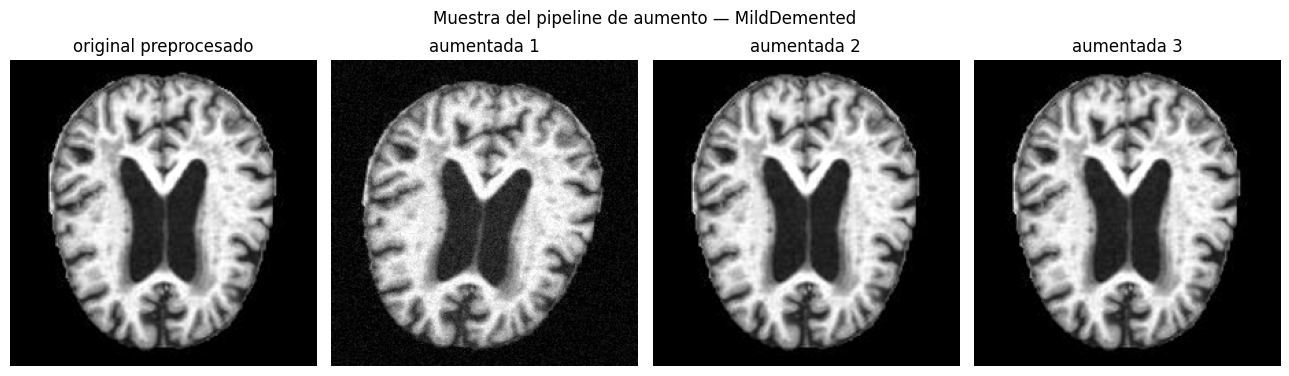

In [12]:
# ============================================================
# 9b. Verificación visual del aumento
# ============================================================
import matplotlib.pyplot as plt

sample_rel = folds[0]["train"][0]
sample_pre = preprocess_image(load_gray(DATA_ROOT / sample_rel))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.9))
axes[0].imshow(sample_pre, cmap="gray")
axes[0].set_title("original preprocesado")
for j in range(3):
    aug = augment_image(sample_pre, stable_seed(SEED, sample_rel, j))
    axes[j + 1].imshow(aug, cmap="gray")
    axes[j + 1].set_title(f"aumentada {j + 1}")
for ax in axes:
    ax.axis("off")
fig.suptitle("Muestra del pipeline de aumento — " + sample_rel.split("/")[1])
fig.tight_layout()
plt.show()

In [13]:
# ============================================================
# 10. Utilidades de entrenamiento e inferencia (YOLOv5-cls)
# ============================================================
import math
import urllib.request
from copy import deepcopy
from datetime import datetime

import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset

# --- Módulos del repositorio oficial ultralytics/yolov5 (commit fijado) ---
from models.experimental import attempt_load
from utils.augmentations import classify_transforms, IMAGENET_MEAN, IMAGENET_STD
from utils.dataloaders import create_classification_dataloader
from utils.general import init_seeds
from utils.torch_utils import (
    GradScaler,
    ModelEMA,
    reshape_classifier_output,
    smart_amp_autocast,
    smart_optimizer,
    smartCrossEntropyLoss,
)

# Pesos preentrenados (ImageNet) de yolov5n-cls
if not YOLO_WEIGHTS_PATH.exists() or YOLO_WEIGHTS_PATH.stat().st_size < 1e5:
    print("Descargando", YOLO_WEIGHTS, "...")
    urllib.request.urlretrieve(YOLO_WEIGHTS_URL, str(YOLO_WEIGHTS_PATH))
assert YOLO_WEIGHTS_PATH.stat().st_size > 1e5, "Descarga de pesos incompleta"
print("Pesos base:", YOLO_WEIGHTS_PATH, f"({YOLO_WEIGHTS_PATH.stat().st_size / 1e6:.1f} MB)")

# Verificación: el transform de inferencia/validación es determinista
_tf_check = classify_transforms(IMGSZ)
_img_gray = preprocess_image(load_gray(DATA_ROOT / folds[0]["train"][0]))
_img_bgr = cv2.cvtColor(_img_gray, cv2.COLOR_GRAY2BGR)      # YOLOv5 espera BGR (cv2)

_v1 = _tf_check(_img_bgr).numpy()
_v2 = _tf_check(_img_bgr).numpy()
print("Transform determinista:", bool(np.array_equal(_v1, _v2)),
      "| forma:", _v1.shape, "| rango: [%.2f, %.2f]" % (_v1.min(), _v1.max()))


def _seed_everything(seed):
    """Semillas + modo determinista.

    init_seeds(deterministic=True) de YOLOv5 activa use_deterministic_algorithms(True),
    que lanza error en CUDA con AdaptiveAvgPool2d (cabeza Classify). Se usa warn_only.
    """
    init_seeds(seed, deterministic=False)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass


def _make_loader(path, shuffle, batch):
    """Dataloader oficial de YOLOv5-cls SIN aumento en línea (augment=False)."""
    return create_classification_dataloader(
        path=path, imgsz=IMGSZ, batch_size=batch, augment=False,
        cache=False, rank=-1, workers=WORKERS, shuffle=shuffle,
    )


@torch.no_grad()
def _evaluate(net, loader, device):
    """Devuelve (top-1, pérdida de entropía cruzada) sobre un dataloader."""
    net.eval()
    loss_sum, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device)
        with smart_amp_autocast(device.type != "cpu"):
            out = net(xb)
        if isinstance(out, (tuple, list)):
            out = out[0]
        out = out.float()
        loss_sum += float(F.cross_entropy(out, yb, reduction="sum"))
        correct += int((out.argmax(1) == yb).sum())
        total += int(yb.numel())
    return correct / max(total, 1), loss_sum / max(total, 1)


def load_v5_model(weights_path, device=None, fuse=False):
    """Carga un checkpoint de YOLOv5-cls en FP32 y modo eval. names -> dict {idx: clase}."""
    device = TORCH_DEVICE if device is None else torch.device(device)
    net = attempt_load(str(weights_path), device=device, fuse=fuse)
    net = net.float().eval()
    if isinstance(net.names, (list, tuple)):
        net.names = dict(enumerate(net.names))
    return net


def train_yolo(data_dir, run_name, epochs=EPOCHS):
    """Entrena YOLOv5n-cls (fine-tuning completo) y devuelve (run_dir, historial).

    Usa solo data_dir/train y data_dir/val. data_dir/test NO se toca.
    Escribe run_dir/weights/{best,last}.pt y run_dir/results.csv con las mismas
    columnas que YOLOv8 (train/loss, val/loss, metrics/accuracy_top1).
    """
    data_dir = Path(data_dir)
    device = TORCH_DEVICE
    cuda = device.type != "cpu"

    run_dir = RUNS_DIR / run_name
    if run_dir.exists():
        shutil.rmtree(run_dir)
    wdir = run_dir / "weights"
    wdir.mkdir(parents=True)
    last_pt, best_pt = wdir / "last.pt", wdir / "best.pt"

    _seed_everything(SEED)

    # ---- datos (sin aumento en línea; el offline ya está en disco) ----
    train_loader = _make_loader(data_dir / "train", True, BATCH)
    val_loader = _make_loader(data_dir / "val", False, BATCH * 2)
    assert train_loader.dataset.album_transforms is None, "El aumento en línea debe estar apagado"
    classes = list(train_loader.dataset.classes)
    assert classes == list(CLASSES), f"Orden de clases distinto: {classes} vs {CLASSES}"
    nc = len(classes)
    nb = len(train_loader)

    # ---- modelo ----
    model = attempt_load(str(YOLO_WEIGHTS_PATH), device="cpu", fuse=False)
    reshape_classifier_output(model, nc)          # cabeza 1000 -> nc clases
    for p in model.parameters():
        p.requires_grad = True
    model.names = classes
    model = model.to(device)

    optimizer = smart_optimizer(model, OPTIMIZER, LR0, momentum=0.9, decay=WEIGHT_DECAY)
    ema = ModelEMA(model)
    criterion = smartCrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    scaler = GradScaler(enabled=cuda)

    # Muestra fija de train para la curva de exactitud de entrenamiento
    ds = train_loader.dataset
    rng = np.random.default_rng(SEED)
    idx = sorted(rng.choice(len(ds), size=min(256, len(ds)), replace=False).tolist())
    acc_loader = DataLoader(Subset(ds, idx), batch_size=32, shuffle=False, num_workers=0)

    def lf(e):                                     # coseno de 1 a LRF
        return ((1 - math.cos(e * math.pi / epochs)) / 2) * (LRF - 1) + 1

    warm_iters = max(round(WARMUP_EPOCHS * nb), 100)
    state = {"epoch": [], "train_acc": []}
    rows, best_fitness = [], -1.0

    print(f"{'Epoch':>8}{'train_loss':>12}{'val_loss':>11}{'val_top1':>10}{'train_top1':>12}{'lr':>10}")
    for epoch in range(epochs):
        model.train()
        base_lr = LR0 * lf(epoch)
        tloss = 0.0
        for i, (xb, yb) in enumerate(train_loader):
            ni = epoch * nb + i
            lr = base_lr * min(1.0, ni / warm_iters)       # warmup lineal
            for g in optimizer.param_groups:
                g["lr"] = lr

            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device)
            with smart_amp_autocast(cuda):
                loss = criterion(model(xb), yb)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            ema.update(model)
            tloss = (tloss * i + loss.item()) / (i + 1)

        val_acc, val_loss = _evaluate(ema.ema, val_loader, device)   # EMA, como en YOLOv5
        tr_acc, _ = _evaluate(model, acc_loader, device)

        fitness = val_acc
        best_fitness = max(best_fitness, fitness)
        ckpt = {
            "epoch": epoch,
            "best_fitness": best_fitness,
            "model": deepcopy(ema.ema).half(),
            "ema": None,
            "updates": ema.updates,
            "optimizer": None,
            "date": datetime.now().isoformat(),
        }
        torch.save(ckpt, last_pt)
        if best_fitness == fitness:
            torch.save(ckpt, best_pt)
        del ckpt

        state["epoch"].append(epoch + 1)
        state["train_acc"].append(float(tr_acc))
        rows.append({"epoch": epoch + 1, "train/loss": tloss, "val/loss": val_loss,
                     "metrics/accuracy_top1": val_acc, "lr/0": lr})
        pd.DataFrame(rows).to_csv(run_dir / "results.csv", index=False)
        print(f"{epoch + 1:>4}/{epochs:<3}{tloss:>12.4f}{val_loss:>11.4f}"
              f"{val_acc:>10.4f}{tr_acc:>12.4f}{lr:>10.2e}")

    print(f"Mejor val top-1: {best_fitness:.4f} | pesos: {best_pt}")

    del model, ema, optimizer, scaler, train_loader, val_loader, acc_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return run_dir, state


@torch.no_grad()
def predict_probs(weights_path, paths, batch=BATCH):
    """Devuelve matriz (n, n_clases) de probabilidades en el orden de CLASSES."""
    net = load_v5_model(weights_path)
    tf = classify_transforms(IMGSZ)
    out = np.zeros((len(paths), len(CLASSES)), dtype=np.float32)

    for i in range(0, len(paths), batch):
        chunk = paths[i:i + batch]
        ims = []
        for p in chunk:
            im = cv2.imread(str(p))                      # BGR, como espera YOLOv5
            if im is None:
                raise IOError(f"No se pudo leer {p}")
            ims.append(tf(im))
        xb = torch.stack(ims).to(TORCH_DEVICE)
        logits = net(xb)
        if isinstance(logits, (tuple, list)):
            logits = logits[0]
        pr = logits.float().softmax(1).cpu().numpy()
        for src_i, cname in net.names.items():
            out[i:i + len(chunk), CLASS_TO_IDX[cname]] = pr[:, src_i]

    del net
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return out


print("Utilidades listas.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Descargando yolov5n-cls.pt ...
Pesos base: /content/yolov5/yolov5n-cls.pt (5.1 MB)
Transform determinista: True | forma: (3, 224, 224) | rango: [-2.12, 2.64]
Utilidades listas.


In [14]:
# ============================================================
# 11. Entrenamiento y evaluación de los 5 folds
# ============================================================
# Restauración desde Drive: si Colab se reinició, /content se perdió pero
# los artefactos ya copiados a Drive permiten reanudar sin repetir folds.
for fold in folds:
    k = fold["fold"]
    wdir = LOCAL_PROJECT / "weights" / f"fold_{k}"
    wdir.mkdir(parents=True, exist_ok=True)
    drive_fold = DRIVE_PROJECT / "weights" / f"fold_{k}"

    for fname in ("best.pt", "last.pt"):
        src_d, dst_l = drive_fold / fname, wdir / fname
        if src_d.exists() and not dst_l.exists():
            shutil.copy2(src_d, dst_l)
            print(f"[fold {k}] restaurado {fname} desde Drive")

    for fname in (f"fold_{k}_probs.npz", f"results_fold_{k}.csv",
                  f"fold_{k}_train_acc.json"):
        src_d = DRIVE_PROJECT / "reports" / fname
        dst_l = LOCAL_PROJECT / "reports" / fname
        if src_d.exists() and not dst_l.exists():
            shutil.copy2(src_d, dst_l)

    manifest_d = DRIVE_PROJECT / "splits" / f"manifest_fold_{k}.csv"
    manifest_l = LOCAL_PROJECT / "splits" / f"manifest_fold_{k}.csv"
    if manifest_d.exists() and not manifest_l.exists():
        shutil.copy2(manifest_d, manifest_l)

# Reanudable: si un fold ya tiene best.pt y probs, se omite.
for fold in folds:
    k = fold["fold"]
    wdir = LOCAL_PROJECT / "weights" / f"fold_{k}"
    wdir.mkdir(parents=True, exist_ok=True)
    probs_file = LOCAL_PROJECT / "reports" / f"fold_{k}_probs.npz"
    hist_file = LOCAL_PROJECT / "reports" / f"fold_{k}_train_acc.json"

    if probs_file.exists() and (wdir / "best.pt").exists():
        print(f"[fold {k}] ya completado, se omite")
        continue

    print("\n" + "=" * 72)
    print(f"FOLD {k}/{N_FOLDS}")
    print("=" * 72)

    t0 = time.time()
    data_dir = GEN_ROOT / f"fold_{k}"
    counts, _ = generate_dataset(f"fold_{k}", fold["train"], fold["val"],
                                 fold["test"], data_dir)
    print_counts(f"fold_{k}", counts)
    print(f"Generación: {time.time() - t0:.1f} s")

    shutil.copy2(data_dir / "manifest.csv",
                 LOCAL_PROJECT / "splits" / f"manifest_fold_{k}.csv")

    run_dir, state = train_yolo(
        data_dir, f"yolov5n_cls_cv_fold{k}_{IMGSZ}px_{EPOCHS}ep"
    )

    for fname in ("best.pt", "last.pt"):
        src = run_dir / "weights" / fname
        if src.exists():
            shutil.copy2(src, wdir / fname)

    # Curvas: conservar results.csv aunque se borre la carpeta de la corrida
    if (run_dir / "results.csv").exists():
        shutil.copy2(run_dir / "results.csv",
                     LOCAL_PROJECT / "reports" / f"results_fold_{k}.csv")

    # Evaluación sobre el fold de test (original, nunca aumentado)
    test_dir = data_dir / "test"
    test_paths, y_true = [], []
    for cls in CLASSES:
        for p in sorted((test_dir / cls).glob("*.jpg")):
            test_paths.append(p)
            y_true.append(CLASS_TO_IDX[cls])

    t1 = time.time()
    probs = predict_probs(wdir / "best.pt", test_paths)
    print(f"Inferencia sobre test: {time.time() - t1:.1f} s")

    np.savez_compressed(probs_file,
                        probs=probs,
                        y_true=np.array(y_true),
                        paths=np.array([str(p) for p in test_paths]))
    with open(hist_file, "w", encoding="utf-8") as fh:
        json.dump(state, fh, indent=2)

    # Persistir en Drive inmediatamente
    drive_fold = DRIVE_PROJECT / "weights" / f"fold_{k}"
    drive_fold.mkdir(parents=True, exist_ok=True)
    for fname in ("best.pt", "last.pt"):
        if (wdir / fname).exists():
            shutil.copy2(wdir / fname, drive_fold / fname)
    shutil.copy2(probs_file, DRIVE_PROJECT / "reports" / probs_file.name)
    if (LOCAL_PROJECT / "reports" / f"results_fold_{k}.csv").exists():
        shutil.copy2(LOCAL_PROJECT / "reports" / f"results_fold_{k}.csv",
                     DRIVE_PROJECT / "reports" / f"results_fold_{k}.csv")

    print(f"[fold {k}] completado en {(time.time() - t0) / 60:.1f} min")

    if not KEEP_GENERATED:
        shutil.rmtree(data_dir, ignore_errors=True)

print("\n✔ Validación cruzada finalizada")


FOLD 1/5


fold_1/val:   0%|          | 0/524 [00:00<?, ?it/s]

fold_1/test:   0%|          | 0/1285 [00:00<?, ?it/s]

fold_1/train:   0%|          | 0/4591 [00:00<?, ?it/s]


fold_1
Clase                     train     val    test
-----------------------------------------------
MildDemented               3870      67     184
ModerateDemented            768       5      11
NonDemented                6864     272     640
VeryMildDemented           6440     180     450
-----------------------------------------------
TOTAL                     17942     524    1285
Generación: 89.9 s
optimizer: AdamW(lr=0.001) with parameter groups 32 weight(decay=0.0), 33 weight(decay=0.0005), 33 bias
   Epoch  train_loss   val_loss  val_top1  train_top1        lr
   1/20       0.7640     0.6158    0.7500      0.8789  3.33e-04
   2/20       0.3457     0.5520    0.8206      0.9219  6.62e-04
   3/20       0.2583     0.5153    0.8015      0.9531  9.75e-04
   4/20       0.1954     0.4287    0.8740      0.9258  9.46e-04
   5/20       0.1435     0.4758    0.8855      0.9375  9.05e-04
   6/20       0.1007     0.4388    0.8721      0.9531  8.55e-04
   7/20       0.0795     0.5115    0.

...


fold_4
Clase                     train     val    test
-----------------------------------------------
MildDemented               3834      69     188
ModerateDemented            768       5      11
NonDemented                6906     262     636
VeryMildDemented           6444     174     455
-----------------------------------------------
TOTAL                     17952     510    1290
Generación: 86.1 s
optimizer: AdamW(lr=0.001) with parameter groups 32 weight(decay=0.0), 33 weight(decay=0.0005), 33 bias
   Epoch  train_loss   val_loss  val_top1  train_top1        lr
   1/20       0.7638     0.6403    0.7686      0.8398  3.33e-04
   2/20       0.3486     0.7671    0.7216      0.8516  6.62e-04
   3/20       0.2608     0.4285    0.8569      0.9258  9.75e-04
   4/20       0.1961     0.4130    0.8902      0.9062  9.46e-04
   5/20       0.1453     0.2709    0.9176      0.9766  9.05e-04
   6/20       0.1019     0.4830    0.9059      0.8828  8.55e-04
   7/20       0.0865     0.3070    0.

fold_5/val:   0%|          | 0/522 [00:00<?, ?it/s]

fold_5/test:   0%|          | 0/1274 [00:00<?, ?it/s]

fold_5/train:   0%|          | 0/4604 [00:00<?, ?it/s]


fold_5
Clase                     train     val    test
-----------------------------------------------
MildDemented               3876      73     177
ModerateDemented            752       4      13
NonDemented                6900     264     636
VeryMildDemented           6444     181     448
-----------------------------------------------
TOTAL                     17972     522    1274
Generación: 76.2 s
optimizer: AdamW(lr=0.001) with parameter groups 32 weight(decay=0.0), 33 weight(decay=0.0005), 33 bias
   Epoch  train_loss   val_loss  val_top1  train_top1        lr
   1/20       0.7678     0.7606    0.7241      0.7773  3.33e-04
   2/20       0.3493     1.0346    0.6571      0.7930  6.62e-04
   3/20       0.2623     2.2623    0.5632      0.5234  9.75e-04
   4/20       0.1965     0.4076    0.8467      0.9727  9.46e-04
   5/20       0.1378     0.4210    0.8908      0.9414  9.05e-04
   6/20       0.1026     0.4686    0.8582      0.9688  8.55e-04
   7/20       0.0816     0.3413    0.

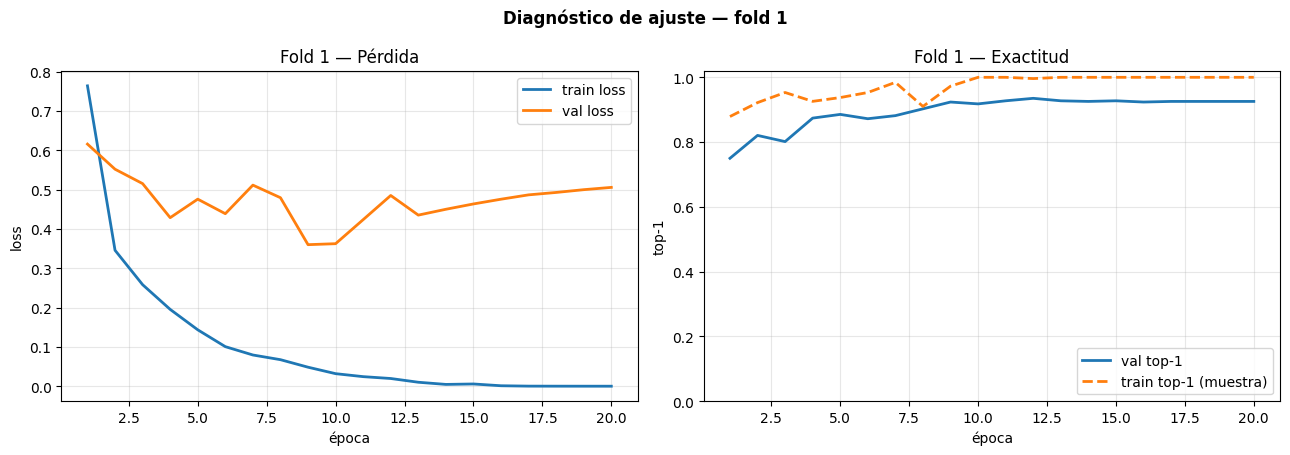

Guardado: /content/work_yolo5_cv/Yolo_5_CV/reports/training_curves/fold_1.png


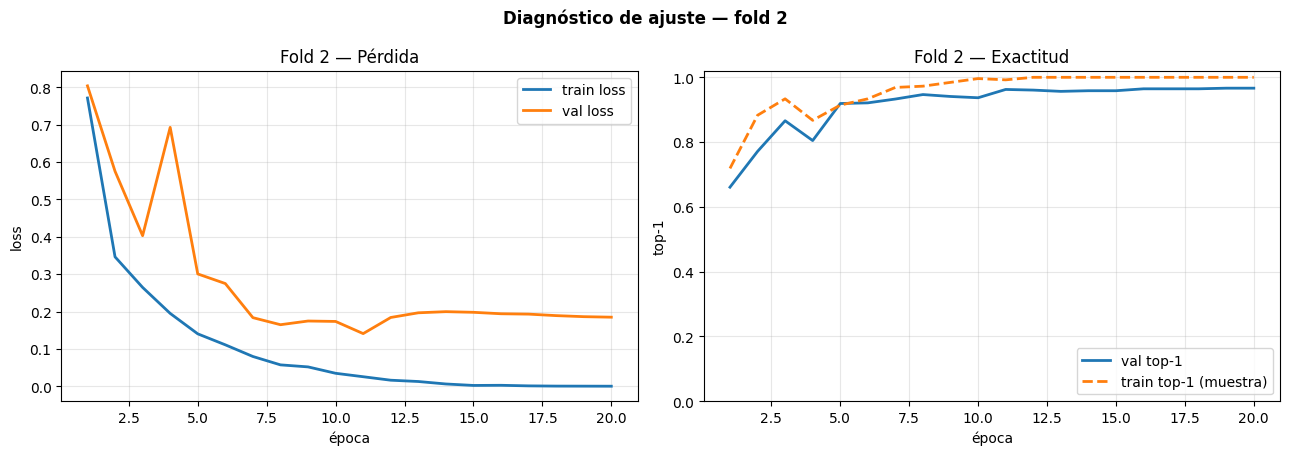

Guardado: /content/work_yolo5_cv/Yolo_5_CV/reports/training_curves/fold_2.png


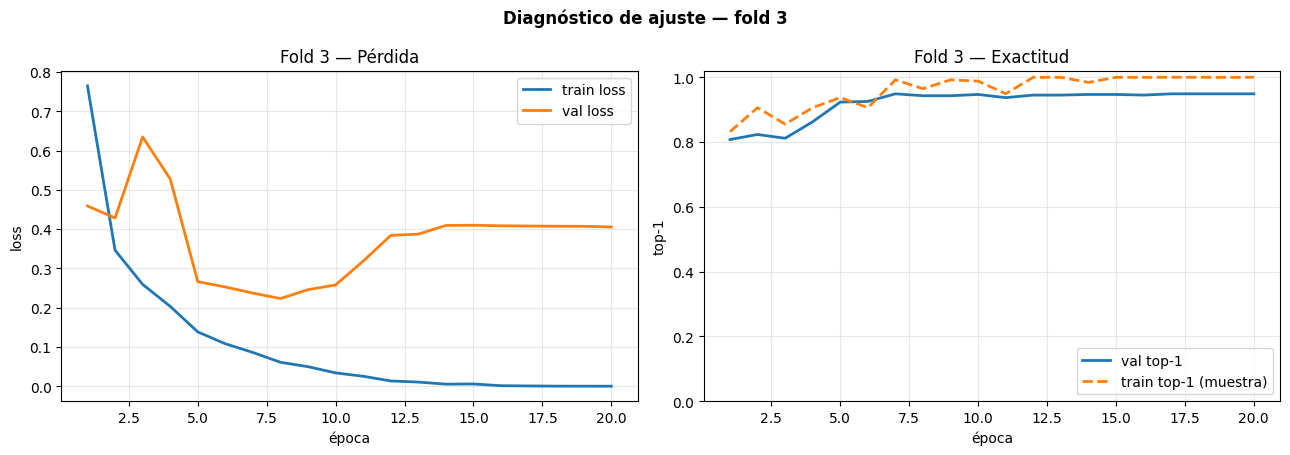

Guardado: /content/work_yolo5_cv/Yolo_5_CV/reports/training_curves/fold_3.png


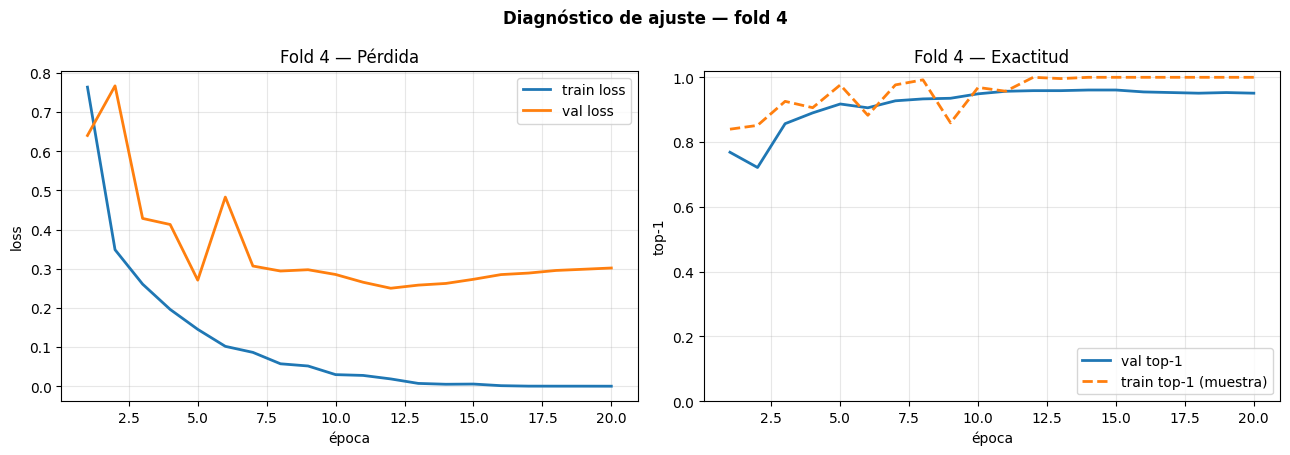

Guardado: /content/work_yolo5_cv/Yolo_5_CV/reports/training_curves/fold_4.png


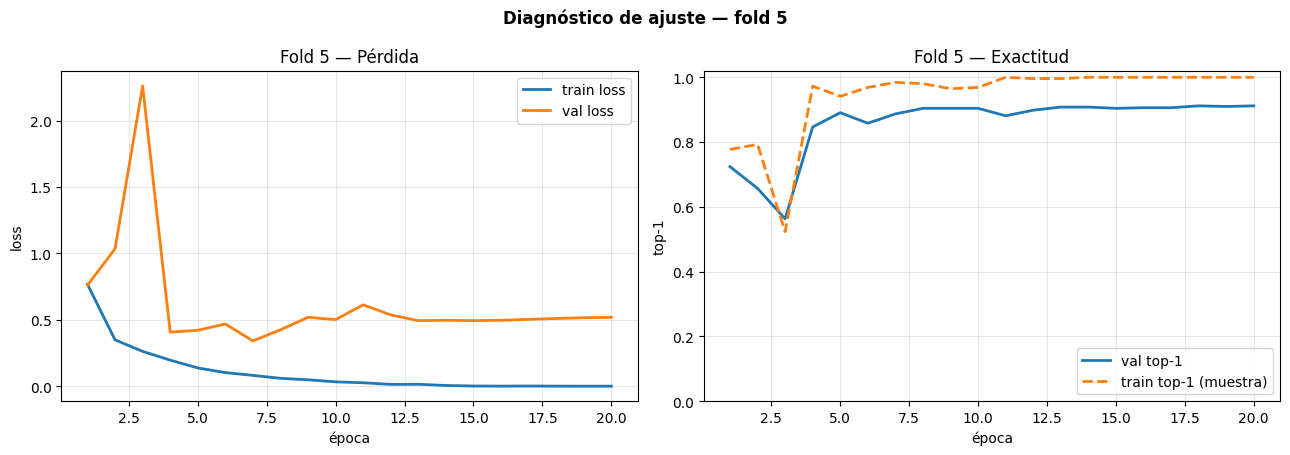

Guardado: /content/work_yolo5_cv/Yolo_5_CV/reports/training_curves/fold_5.png


In [15]:
# ============================================================
# 12. Curvas de overfitting / underfitting por fold
# ============================================================
import matplotlib.pyplot as plt

CURVES_DIR = LOCAL_PROJECT / "reports" / "training_curves"
CURVES_DIR.mkdir(parents=True, exist_ok=True)


def _find_col(df, *needles):
    for c in df.columns:
        for nd in needles:
            if nd in c:
                return c
    return None


for fold in folds:
    k = fold["fold"]
    csv = LOCAL_PROJECT / "reports" / f"results_fold_{k}.csv"
    if not csv.exists():
        csv = RUNS_DIR / f"yolov5n_cls_cv_fold{k}_{IMGSZ}px_{EPOCHS}ep" / "results.csv"
    if not csv.exists():
        print(f"[fold {k}] sin results.csv, se omite")
        continue

    df = pd.read_csv(csv)
    df.columns = [c.strip() for c in df.columns]

    c_tr = _find_col(df, "train/loss")
    c_va = _find_col(df, "val/loss")
    c_acc = _find_col(df, "accuracy_top1")
    ep = df["epoch"] if "epoch" in df.columns else np.arange(1, len(df) + 1)

    hist_file = LOCAL_PROJECT / "reports" / f"fold_{k}_train_acc.json"
    hist = {"epoch": [], "train_acc": []}
    if hist_file.exists():
        with open(hist_file, encoding="utf-8") as fh:
            hist = json.load(fh)

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

    if c_tr is not None:
        ax[0].plot(ep, df[c_tr], label="train loss", lw=2)
    if c_va is not None:
        ax[0].plot(ep, df[c_va], label="val loss", lw=2)
    ax[0].set_title(f"Fold {k} — Pérdida")
    ax[0].set_xlabel("época")
    ax[0].set_ylabel("loss")
    ax[0].grid(alpha=0.3)
    ax[0].legend()

    if c_acc is not None:
        ax[1].plot(ep, df[c_acc], label="val top-1", lw=2)
    if len(hist.get("train_acc", [])):
        ax[1].plot(hist["epoch"], hist["train_acc"],
                   label="train top-1 (muestra)", lw=2, ls="--")
    ax[1].set_title(f"Fold {k} — Exactitud")
    ax[1].set_xlabel("época")
    ax[1].set_ylabel("top-1")
    ax[1].set_ylim(0, 1.02)
    ax[1].grid(alpha=0.3)
    ax[1].legend(loc="lower right")

    fig.suptitle(f"Diagnóstico de ajuste — fold {k}", fontweight="bold")
    fig.tight_layout()
    out = CURVES_DIR / f"fold_{k}.png"
    fig.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Guardado:", out)

Predicciones OOF: (6400, 4)
Top-1 accuracy global: 0.9477
Macro F1             : 0.9513

Métricas por fold
 fold  n_test  accuracy  macro_f1  precision_MildDemented  recall_MildDemented  f1_MildDemented  precision_ModerateDemented  recall_ModerateDemented  f1_ModerateDemented  precision_NonDemented  recall_NonDemented  f1_NonDemented  precision_VeryMildDemented  recall_VeryMildDemented  f1_VeryMildDemented
    1    1285    0.9525    0.9627                  0.9770               0.9239           0.9497                         1.0                   1.0000               1.0000                 0.9455              0.9766          0.9608                      0.9522                   0.9289               0.9404
    2    1270    0.9449    0.9517                  0.9565               0.8652           0.9086                         1.0                   1.0000               1.0000                 0.9303              0.9766          0.9529                      0.9622                   0.9292      

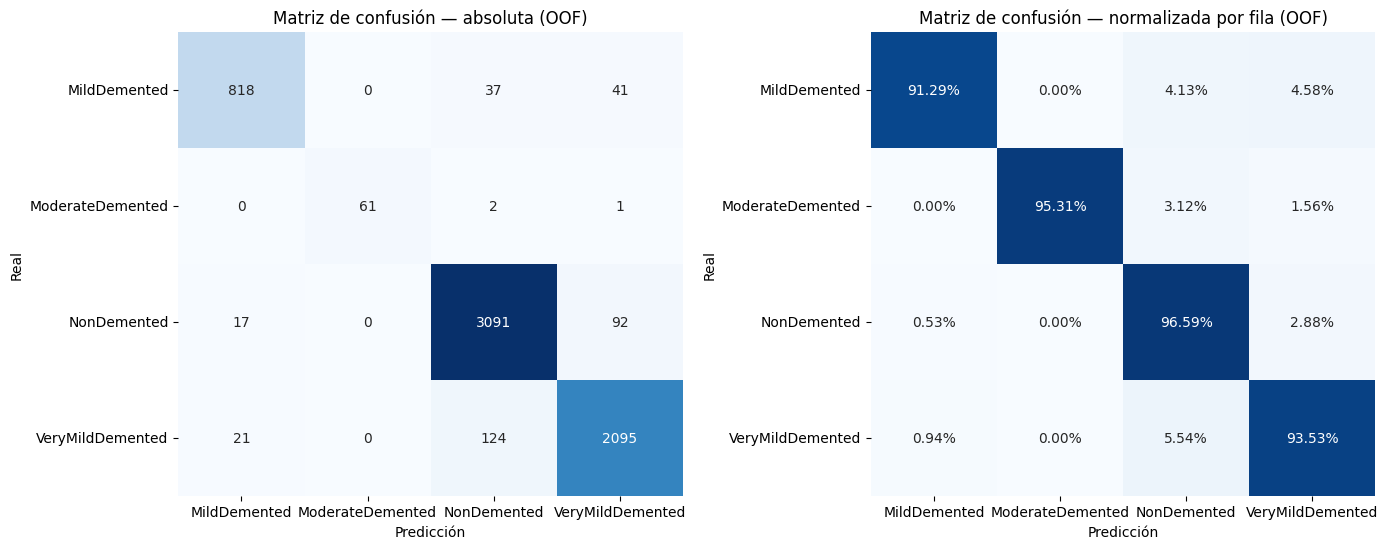

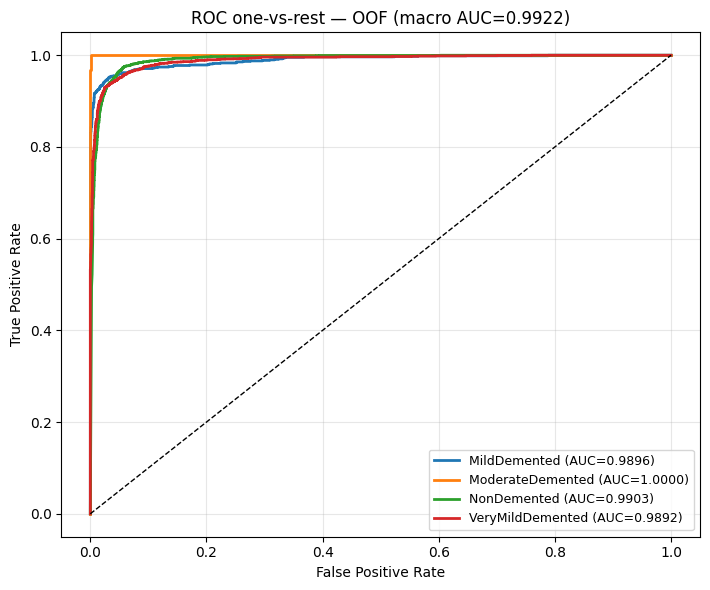

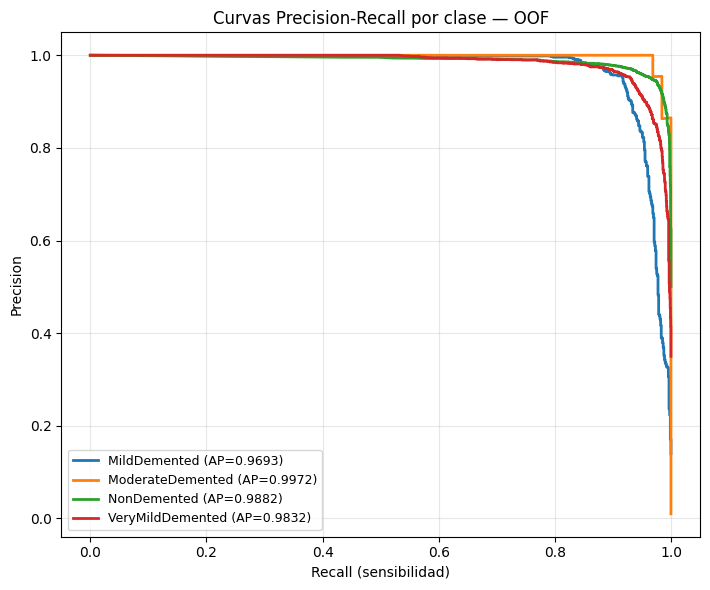


Guardado: reports/oof_predictions.csv


In [16]:
# ============================================================
# 13. Métricas agregadas out-of-fold (6,400 predicciones)
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc,
    precision_recall_curve, average_precision_score, f1_score,
)

probs_list, y_list = [], []
for fold in folds:
    f = LOCAL_PROJECT / "reports" / f"fold_{fold['fold']}_probs.npz"
    assert f.exists(), f"Falta {f}. Ejecuta la celda 11."
    d = np.load(f, allow_pickle=True)
    probs_list.append(d["probs"])
    y_list.append(d["y_true"])

probs_oof = np.vstack(probs_list)
y_oof = np.concatenate(y_list)
y_pred = probs_oof.argmax(1)

print("Predicciones OOF:", probs_oof.shape)
print("Top-1 accuracy global: %.4f" % accuracy_score(y_oof, y_pred))
print("Macro F1             : %.4f" % f1_score(y_oof, y_pred, average="macro"))

# ---------- métricas por fold ----------
rows = []
for fold in folds:
    d = np.load(LOCAL_PROJECT / "reports" / f"fold_{fold['fold']}_probs.npz",
                allow_pickle=True)
    p, yt = d["probs"], d["y_true"]
    yp = p.argmax(1)
    rep = classification_report(yt, yp, labels=list(range(len(CLASSES))),
                                target_names=CLASSES, output_dict=True,
                                zero_division=0)
    row = {"fold": fold["fold"], "n_test": int(len(yt)),
           "accuracy": float(accuracy_score(yt, yp)),
           "macro_f1": float(f1_score(yt, yp, average="macro", zero_division=0))}
    for cls in CLASSES:
        row[f"precision_{cls}"] = float(rep[cls]["precision"])
        row[f"recall_{cls}"] = float(rep[cls]["recall"])
        row[f"f1_{cls}"] = float(rep[cls]["f1-score"])
    rows.append(row)

fold_df = pd.DataFrame(rows)
fold_df.to_csv(LOCAL_PROJECT / "reports" / "fold_metrics.csv", index=False)
print("\nMétricas por fold")
print(fold_df.round(4).to_string(index=False))

# ---------- resumen global ----------
summary = {
    "n_total": int(len(y_oof)),
    "top1_accuracy": float(accuracy_score(y_oof, y_pred)),
    "macro_f1": float(f1_score(y_oof, y_pred, average="macro")),
    "roc_auc_macro_ovr": float(roc_auc_score(y_oof, probs_oof,
                                             multi_class="ovr", average="macro")),
    "per_class": {},
    "cv_mean": {c: float(fold_df[c].mean()) for c in fold_df.columns
                if c not in ("fold", "n_test")},
    "cv_std": {c: float(fold_df[c].std(ddof=0)) for c in fold_df.columns
               if c not in ("fold", "n_test")},
}

for i, cls in enumerate(CLASSES):
    yb = (y_oof == i).astype(int)
    summary["per_class"][cls] = {
        "support": int(yb.sum()),
        "auc_ovr": float(roc_auc_score(yb, probs_oof[:, i])),
        "average_precision": float(average_precision_score(yb, probs_oof[:, i])),
    }

with open(LOCAL_PROJECT / "reports" / "cv_summary.json", "w", encoding="utf-8") as fh:
    json.dump(summary, fh, indent=2, ensure_ascii=False)
print("\nResumen CV")
print(json.dumps(summary, indent=2, ensure_ascii=False))

# ---------- classification report ----------
rep_txt = classification_report(y_oof, y_pred, labels=list(range(len(CLASSES))),
                                target_names=CLASSES, digits=4, zero_division=0)
print("\nClassification report (OOF)")
print(rep_txt)
with open(LOCAL_PROJECT / "reports" / "classification_report.txt",
          "w", encoding="utf-8") as fh:
    fh.write(rep_txt)

# ---------- matriz de confusión ----------
cm = confusion_matrix(y_oof, y_pred, labels=list(range(len(CLASSES))))
cm_norm = cm.astype(float) / np.clip(cm.sum(1, keepdims=True), 1, None)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("Matriz de confusión — absoluta (OOF)")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Real")

sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues", vmin=0, vmax=1,
            cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title("Matriz de confusión — normalizada por fila (OOF)")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Real")

fig.tight_layout()
fig.savefig(LOCAL_PROJECT / "reports" / "confusion_matrix_oof.png",
            dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---------- ROC one-vs-rest ----------
fig, ax = plt.subplots(figsize=(7.2, 6))
for i, cls in enumerate(CLASSES):
    yb = (y_oof == i).astype(int)
    fpr, tpr, _ = roc_curve(yb, probs_oof[:, i])
    ax.plot(fpr, tpr, lw=2,
            label=f"{cls} (AUC={auc(fpr, tpr):.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC one-vs-rest — OOF "
             f"(macro AUC={summary['roc_auc_macro_ovr']:.4f})")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(LOCAL_PROJECT / "reports" / "roc_curves_oof.png",
            dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---------- Precision-Recall ----------
fig, ax = plt.subplots(figsize=(7.2, 6))
for i, cls in enumerate(CLASSES):
    yb = (y_oof == i).astype(int)
    pr, rc, _ = precision_recall_curve(yb, probs_oof[:, i])
    ap = average_precision_score(yb, probs_oof[:, i])
    ax.plot(rc, pr, lw=2, label=f"{cls} (AP={ap:.4f})")
ax.set_xlabel("Recall (sensibilidad)")
ax.set_ylabel("Precision")
ax.set_title("Curvas Precision-Recall por clase — OOF")
ax.legend(loc="lower left", fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(LOCAL_PROJECT / "reports" / "pr_curves_oof.png",
            dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---------- predicciones OOF ----------
oof_df = pd.DataFrame({
    "y_true": [CLASSES[i] for i in y_oof],
    "y_pred": [CLASSES[i] for i in y_pred],
})
for i, cls in enumerate(CLASSES):
    oof_df[f"prob_{cls}"] = probs_oof[:, i]
oof_df.to_csv(LOCAL_PROJECT / "reports" / "oof_predictions.csv", index=False)
print("\nGuardado: reports/oof_predictions.csv")

In [17]:
# ============================================================
# 14. Modelo final (100 % de los datos originales + aumentados)
# ============================================================
all_rels = df_idx["rel"].tolist()
final_val = folds[0]["val"]          # solo monitoreo / selección de checkpoint
FINAL_DIR = GEN_ROOT / "final"

final_counts, _ = generate_dataset(
    "final", all_rels, final_val, [], FINAL_DIR
)
print_counts("final", final_counts)

final_run_dir, final_state = train_yolo(
    FINAL_DIR, f"yolov5n_cls_final_{IMGSZ}px_{EPOCHS}ep"
)

FINAL_WDIR = LOCAL_PROJECT / "weights" / "final"
FINAL_WDIR.mkdir(parents=True, exist_ok=True)
for fname in ("best.pt", "last.pt"):
    src = final_run_dir / "weights" / fname
    if src.exists():
        shutil.copy2(src, FINAL_WDIR / fname)

with open(LOCAL_PROJECT / "reports" / "final_train_acc.json", "w",
          encoding="utf-8") as fh:
    json.dump(final_state, fh, indent=2)

if (final_run_dir / "results.csv").exists():
    shutil.copy2(final_run_dir / "results.csv",
                 LOCAL_PROJECT / "reports" / "results_final.csv")

print("\nModelo final guardado en:", FINAL_WDIR)
print("Nota: la métrica oficial proviene de la CV 5-fold, no de este split.")

final/val:   0%|          | 0/524 [00:00<?, ?it/s]

final/test: 0it [00:00, ?it/s]

final/train:   0%|          | 0/6400 [00:00<?, ?it/s]


final
Clase                     train     val    test
-----------------------------------------------
MildDemented               5376      67       0
ModerateDemented           1024       5       0
NonDemented                9600     272       0
VeryMildDemented           8960     180       0
-----------------------------------------------
TOTAL                     24960     524       0
optimizer: AdamW(lr=0.001) with parameter groups 32 weight(decay=0.0), 33 weight(decay=0.0005), 33 bias
   Epoch  train_loss   val_loss  val_top1  train_top1        lr
   1/20       0.7182     0.1891    0.9237      0.9023  3.33e-04
   2/20       0.3023     0.1232    0.9504      0.9336  6.62e-04
   3/20       0.2409     0.0751    0.9714      0.8594  9.76e-04
   4/20       0.1761     0.0582    0.9714      0.9141  9.46e-04
   5/20       0.1252     0.0118    0.9981      0.9648  9.05e-04
   6/20       0.0973     0.0015    1.0000      0.9492  8.55e-04
   7/20       0.0743     0.0006    1.0000      0.9375  7.

In [18]:
# ============================================================
# 15. Exportación a ONNX (artefacto para FastAPI)
# ============================================================
final_best = LOCAL_PROJECT / "weights" / "final" / "best.pt"
assert final_best.exists(), "Primero ejecuta la celda 14"


class V5OnnxWrapper(nn.Module):
    """Entrada RGB [0,1] NCHW -> normaliza (ImageNet) -> YOLOv5-cls -> softmax.

    Así el ONNX recibe la imagen en [0,1] y devuelve probabilidades, sin que el
    backend tenga que replicar la normalización.
    """

    def __init__(self, net):
        super().__init__()
        self.net = net
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))

    def forward(self, x):
        out = self.net((x - self.mean) / self.std)
        if isinstance(out, (tuple, list)):
            out = out[0]
        return out.softmax(1)


net_cpu = load_v5_model(final_best, device="cpu", fuse=False)
wrapper = V5OnnxWrapper(net_cpu).eval()

dest_onnx = LOCAL_PROJECT / "weights" / "final" / "best.onnx"
dummy = torch.rand(1, 3, IMGSZ, IMGSZ)
export_kwargs = dict(input_names=["images"], output_names=["probs"],
                     opset_version=12, do_constant_folding=True)
with torch.no_grad():
    try:
        torch.onnx.export(wrapper, dummy, str(dest_onnx), dynamo=False, **export_kwargs)
    except TypeError:                       # torch antiguo sin el argumento `dynamo`
        torch.onnx.export(wrapper, dummy, str(dest_onnx), **export_kwargs)

try:                                         # equivalente a simplify=True de YOLOv8
    import onnxslim
    onnxslim.slim(str(dest_onnx), str(dest_onnx))
except Exception as e:
    print("onnxslim omitido:", e)

# Verificación numérica ONNX vs PyTorch
import onnxruntime as ort
sess = ort.InferenceSession(str(dest_onnx), providers=["CPUExecutionProvider"])
xt = torch.rand(2, 3, IMGSZ, IMGSZ)
with torch.no_grad():
    ref = wrapper(xt).numpy()
got = np.concatenate([sess.run(None, {"images": xt[j:j + 1].numpy()})[0] for j in range(2)])
max_diff = float(np.abs(ref - got).max())
print("Dif. máx. ONNX vs PyTorch:", max_diff)
assert max_diff < 1e-3, "El ONNX no reproduce al modelo PyTorch"

print("ONNX exportado:", dest_onnx)
print("Tamaño: %.1f MB" % (dest_onnx.stat().st_size / 1e6))
print("Entrada : 'images' float32 [1,3,%d,%d], RGB en [0,1]" % (IMGSZ, IMGSZ))
print("Salida  : 'probs'  float32 [1,%d] (softmax), orden:" % len(CLASSES), CLASSES)


+-------------------+----------------------------+------------------------------------------+
|    Model Name     |         best.onnx          | /content/work_yolo5_cv/Yolo_5_CV/weights |
|                   |                            |             /final/best.onnx             |
+-------------------+----------------------------+------------------------------------------+
|    Model Info     | Op Set: 12 / IR Version: 7 |        Op Set: 12 / IR Version: 7        |
+-------------------+----------------------------+------------------------------------------+
|    IN: images     | float32: (1, 3, 224, 224)  |        float32: (1, 3, 224, 224)         |
|    OUT: probs     |      float32: (1, 4)       |             float32: (1, 4)              |
+-------------------+----------------------------+------------------------------------------+
|        Add        |             7              |                    7                     |
|      Concat       |             4              |          

Por favor, sube la imagen de resonancia magnética (IRM) que deseas analizar:


Saving non_32.jpg to non_32.jpg

Imagen procesada: non_32.jpg

--- SALIDA TIPO JSON PARA FASTAPI ---
{
  "predicted_class": "NonDemented",
  "confidence": 1.0,
  "scores": {
    "MildDemented": 1.2570203124923074e-12,
    "ModerateDemented": 2.1457152439898223e-16,
    "NonDemented": 1.0,
    "VeryMildDemented": 1.8703303350520173e-09
  }
}

Ranking:
  NonDemented          1.0000  (100.0 %)
  VeryMildDemented     0.0000  (  0.0 %)
  MildDemented         0.0000  (  0.0 %)
  ModerateDemented     0.0000  (  0.0 %)


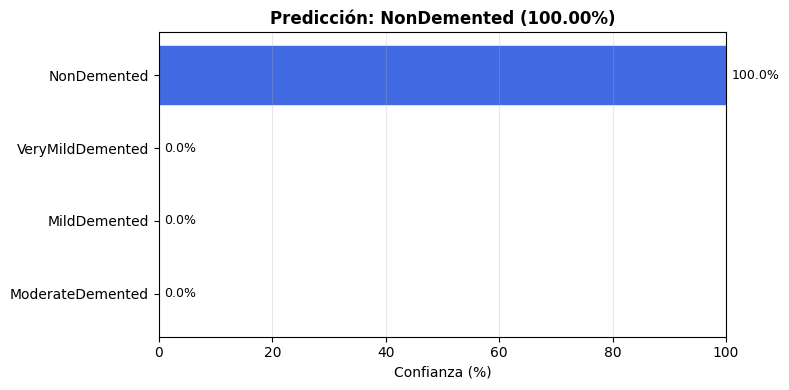

In [19]:
# ===========================================================
# 16. Inferencia unitaria interactiva — JSON para FastAPI y Gráfico de Barras
# ===========================================================
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
# Cargar el modelo final entrenado
model_inf = load_v5_model(LOCAL_PROJECT / "weights" / "final" / "best.pt")
_tf_inf = classify_transforms(IMGSZ)

print("Por favor, sube la imagen de resonancia magnética (IRM) que deseas analizar:")
uploaded = files.upload()

if not uploaded:
    print("No se ha subido ninguna imagen.")
else:
    # Tomar la primera imagen subida
    filename = list(uploaded.keys())[0]
    print(f"\nImagen procesada: {filename}")

    # Leer la imagen subida en escala de grises
    raw = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)
    if raw is None:
        # Fallback por si acaso se subió con canal alfa o formato extraño
        img_bgr_temp = cv2.imread(filename)
        raw = cv2.cvtColor(img_bgr_temp, cv2.COLOR_BGR2GRAY)

    # Preprocesamiento oficial del pipeline
    pre = preprocess_image(raw)
    pre_bgr = cv2.cvtColor(pre, cv2.COLOR_GRAY2BGR)

    # Inferencia con YOLOv5-cls
    with torch.no_grad():
        logits = model_inf(_tf_inf(pre_bgr).unsqueeze(0).to(TORCH_DEVICE))
        if isinstance(logits, (tuple, list)):
            logits = logits[0]
    probs = logits.float().softmax(1)[0].cpu().numpy()
    names = model_inf.names

    # Estructura del JSON para FastAPI
    scores = {names[i]: float(probs[i]) for i in names}
    payload = {
        "predicted_class": names[int(probs.argmax())],
        "confidence": float(probs.max()),
        "scores": scores,
    }

    print("\n--- SALIDA TIPO JSON PARA FASTAPI ---")
    print(json.dumps(payload, indent=2, ensure_ascii=False))

    print("\nRanking:")
    for cname, p in sorted(scores.items(), key=lambda kv: -kv[1]):
        print(f"  {cname:<20} {p:.4f}  ({p * 100:5.1f} %)")

    # --- Generación del Gráfico de Barras ---
    classes_sorted = [k for k, v in sorted(scores.items(), key=lambda kv: kv[1])]
    values_sorted = [v * 100 for k, v in sorted(scores.items(), key=lambda kv: kv[1])]

    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.barh(classes_sorted, values_sorted, color='skyblue')

    # Destacar la barra predicha con otro color
    predicted_label = payload["predicted_class"]
    for i, cname in enumerate(classes_sorted):
        if cname == predicted_label:
            bars[i].set_color('royalblue')

    ax.set_xlim(0, 100)
    ax.set_xlabel('Confianza (%)')
    ax.set_title(f'Predicción: {predicted_label} ({payload["confidence"]*100:.2f}%)', fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

    for bar in bars:
        width = bar.get_width()
        ax.text(width + 1, bar.get_y() + bar.get_height()/2, f'{width:.1f}%',
                va='center', ha='left', fontsize=9)

    fig.tight_layout()
    plt.show()
    plt.close(fig)

Diferencia máx. vs. predictor: 0.0


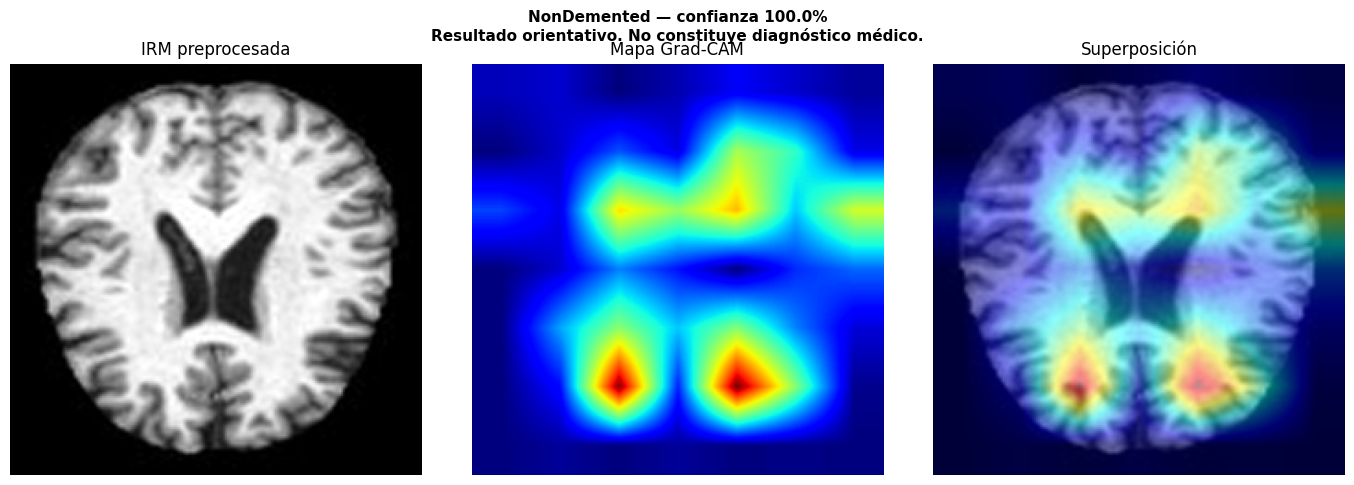

Guardado: /content/work_yolo5_cv/Yolo_5_CV/reports/gradcam/ejemplo_inferencia.png


In [20]:
# ============================================================
# 17. Grad-CAM — explicabilidad sobre la IRM
# ============================================================
import matplotlib.pyplot as plt


class V5GradCAM:
    """Grad-CAM manual para el clasificador YOLOv5-cls (sin dependencias extra)."""

    def __init__(self, weights_path, device=None):
        self.device = TORCH_DEVICE if device is None else torch.device(device)
        self.net = load_v5_model(weights_path, device=self.device, fuse=False)
        self.layer = self._find_target(self.net)
        self.acts = None
        self.grads = None
        self.layer.register_forward_hook(self._fwd)

    @staticmethod
    def _find_target(net):
        """Última capa del backbone: la que alimenta a la cabeza Classify."""
        seq = net.model
        for i in range(len(seq) - 1, 0, -1):
            if seq[i].__class__.__name__ == "Classify":
                return seq[i - 1]
        for m in reversed(list(net.modules())):
            if isinstance(m, torch.nn.Conv2d):
                return m
        raise RuntimeError("No se encontró una capa objetivo para Grad-CAM")

    def _fwd(self, module, inp, out):
        self.acts = out
        if out.requires_grad:
            out.register_hook(self._save_grad)   # hook sobre el tensor (evita problemas con ops in-place)

    def _save_grad(self, grad):
        self.grads = grad

    def __call__(self, img_uint8, class_idx=None):
        # Misma normalización que classify_transforms de YOLOv5 (media/desv. ImageNet, RGB)
        mean = torch.tensor(IMAGENET_MEAN, device=self.device).view(1, 3, 1, 1)
        std = torch.tensor(IMAGENET_STD, device=self.device).view(1, 3, 1, 1)

        x = torch.from_numpy(img_uint8).float().unsqueeze(0).unsqueeze(0) / 255.0
        x = x.repeat(1, 3, 1, 1).to(self.device)
        x = ((x - mean) / std).requires_grad_(True)

        self.acts, self.grads = None, None
        with torch.enable_grad():
            out = self.net(x)
            logits = out[0] if isinstance(out, (tuple, list)) else out
            probs = logits.softmax(1)[0].detach().cpu().numpy()
            if class_idx is None:
                class_idx = int(probs.argmax())
            logits[0, class_idx].backward()

        act = self.acts[0].detach()
        grad = self.grads[0].detach()
        weights = grad.mean(dim=(1, 2), keepdim=True)
        cam = torch.relu((weights * act).sum(dim=0))
        cam = cam / (cam.max() + 1e-8)
        return cam.cpu().numpy(), probs


cam_engine = V5GradCAM(LOCAL_PROJECT / "weights" / "final" / "best.pt")
cam, probs_cam = cam_engine(pre)
pred_idx = int(probs_cam.argmax())
pred_name = CLASSES[pred_idx]
conf = float(probs_cam[pred_idx])

# Consistencia: el forward de Grad-CAM debe reproducir al predictor
if "probs" in globals():
    print("Diferencia máx. vs. predictor:",
          float(np.abs(np.asarray(probs) - probs_cam).max()))

cam_r = cv2.resize(cam, (AUG_SIZE, AUG_SIZE))
heat = cv2.applyColorMap(np.uint8(255 * cam_r), cv2.COLORMAP_JET)
heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)

base = cv2.cvtColor(pre, cv2.COLOR_GRAY2RGB).astype(np.float32) / 255.0
overlay = np.clip(0.55 * base + 0.45 * (heat.astype(np.float32) / 255.0), 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.9))
axes[0].imshow(pre, cmap="gray")
axes[0].set_title("IRM preprocesada")
axes[1].imshow(cam_r, cmap="jet")
axes[1].set_title("Mapa Grad-CAM")
axes[2].imshow(overlay)
axes[2].set_title("Superposición")
for ax in axes:
    ax.axis("off")

fig.suptitle(
    f"{pred_name} — confianza {conf:.1%}\n"
    "Resultado orientativo. No constituye diagnóstico médico.",
    fontweight="bold", fontsize=11,
)
fig.tight_layout()

GRADCAM_DIR = LOCAL_PROJECT / "reports" / "gradcam"
GRADCAM_DIR.mkdir(parents=True, exist_ok=True)
out = GRADCAM_DIR / "ejemplo_inferencia.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Guardado:", out)

In [21]:
# ============================================================
# 18. Empaquetado y copia a Google Drive
# ============================================================
for sub in ("weights/final", "reports", "splits"):
    (DRIVE_PROJECT / sub).mkdir(parents=True, exist_ok=True)

for fname in ("best.pt", "last.pt", "best.onnx"):
    src = LOCAL_PROJECT / "weights" / "final" / fname
    if src.exists():
        shutil.copy2(src, DRIVE_PROJECT / "weights" / "final" / fname)

for base in ("reports", "splits"):
    for p in (LOCAL_PROJECT / base).rglob("*"):
        if p.is_file():
            rel = p.relative_to(LOCAL_PROJECT)
            (DRIVE_PROJECT / rel).parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(p, DRIVE_PROJECT / rel)

print("Artefactos copiados a:", DRIVE_PROJECT)
print("\nResumen final de la CV")
print(json.dumps(summary, indent=2, ensure_ascii=False))

print("\nArchivos en weights/final:")
for p in sorted((DRIVE_PROJECT / "weights" / "final").glob("*")):
    print(f"  {p.name:<12} {p.stat().st_size / 1e6:6.2f} MB")

print("\n⚠️  Resultados orientativos. No constituyen diagnóstico médico.")

Artefactos copiados a: /content/drive/MyDrive/Tallermovil/G1-TCSM-APP_MOVIL/Yolo_5_CV

Resumen final de la CV
{
  "n_total": 6400,
  "top1_accuracy": 0.94765625,
  "macro_f1": 0.9513038684815769,
  "roc_auc_macro_ovr": 0.9922473684085957,
  "per_class": {
    "MildDemented": {
      "support": 896,
      "auc_ovr": 0.9895658271257268,
      "average_precision": 0.9692621319732578
    },
    "ModerateDemented": {
      "support": 64,
      "auc_ovr": 0.9999679411300505,
      "average_precision": 0.9971782862407863
    },
    "NonDemented": {
      "support": 3200,
      "auc_ovr": 0.9903026855468751,
      "average_precision": 0.9881925695758925
    },
    "VeryMildDemented": {
      "support": 2240,
      "auc_ovr": 0.9891530198317307,
      "average_precision": 0.9831693642894328
    }
  },
  "cv_mean": {
    "accuracy": 0.9476631115685231,
    "macro_f1": 0.9524539350323463,
    "precision_MildDemented": 0.9554864028480573,
    "recall_MildDemented": 0.9130880229490629,
    "f1_Mild